# Overlapping redshift bins: joint covariance of several samples

RascalJax computes the joint covariance of the correlation functions of several *samples*. A sample is a
membership-weighted view of a random catalog, so two redshift bins of the same tracer are two samples on one
catalog; where they overlap they share particles, and the shot-noise cross terms between the bins come out of the
same integrals. Samples on different catalogs (different tracers) never share particles.

This notebook uses a periodic box as a stand-in for a survey, with the z coordinate playing the role of
redshift: sample A is the slab $z < 0.6L$ and sample B the slab $z \ge 0.4L$, overlapping in $0.4L \le z < 0.6L$.
The covariance blocks are checked against exact brute-force sums on a small catalog (see
`scripts/bruteforce_multi.py` for the full check).

In [1]:
import os
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import spherical_jn
import rascaljax as rj

In [2]:
k = np.linspace(1e-4, 2.0, 40001)
P = 2e4 * (k / 0.1) / (1 + (k / 0.1) ** 3.5) * np.exp(-((k * 3.0) ** 2))
def xi_of_r(r):
    r = np.atleast_1d(r)
    return np.trapezoid(k[None, :] ** 2 * P[None, :] * spherical_jn(0, k[None, :] * r[:, None]), k, axis=1) / (2 * np.pi**2)
s_tab = np.arange(1.0, 151.0, 1.0)
mu_tab = np.linspace(0.025, 0.975, 20)
table = rj.XiTable.from_model(s_tab, mu_tab, np.repeat(xi_of_r(s_tab)[:, None], len(mu_tab), axis=1))

## Catalog and the two overlapping samples

`Sample.from_redshift_range` builds the membership mask from a per-particle redshift array (here the z coordinate).

In [3]:
L, N = 600.0, 60_000
rng = np.random.default_rng(9)
pos = rng.uniform(0, L, size=(N, 3))
cat = rj.Catalog(pos, np.ones(N), n_data=N / 2, name="box")
z = pos[:, 2]
sA = rj.Sample.from_redshift_range(cat, z, 0.0, 0.6 * L, "A")
sB = rj.Sample.from_redshift_range(cat, z, 0.4 * L, L, "B")
print("particles in A, B, both:", sA.membership.sum(), sB.membership.sum(), (sA.membership * sB.membership).sum())

particles in A, B, both: 36192.0 35873.0 12065.0


## Pair counts for every correlation (AA, AB, BB)

Each correlation function needs its own normalized RR counts (and in a real analysis its own measured xi table
and jackknife counts). With weights summing to 1 over the whole catalog, the normalized counts are
$\sum_{i \neq j} w_i^S w_j^T \Theta_a(ij)$; we count them here with a KD-tree.

In [4]:
from scipy.spatial import cKDTree
s_edges = np.arange(20.0, 81.0, 10.0)
n_mu = 10
binning = rj.Binning(s_edges, n_mu, max_l=2)
tree = cKDTree(pos, boxsize=L)
pairs = tree.query_pairs(s_edges[-1], output_type="ndarray")
i, j = pairs[:, 0], pairs[:, 1]
d = pos[i] - pos[j]; d -= L * np.round(d / L)
r = np.sqrt((d**2).sum(axis=1)); mu = np.abs(d[:, 2]) / r
b = binning.flat_bin(r, mu); ok = b >= 0
i, j, b = i[ok], j[ok], b[ok]
w = cat.weights

def rr_counts(mS, mT):
    ww = w[i] * w[j] * (mS[i] * mT[j] + mS[j] * mT[i])  # both orderings of the pair
    return np.bincount(b, weights=ww, minlength=binning.n_bins).reshape(binning.n_s, n_mu)

samples = [sA, sB]
corrs = {(0, 0): rj.CorrelationInput(s_edges, rr_counts(sA.membership, sA.membership), table),
         (0, 1): rj.CorrelationInput(s_edges, rr_counts(sA.membership, sB.membership), table),
         (1, 1): rj.CorrelationInput(s_edges, rr_counts(sB.membership, sB.membership), table)}

## Run and post-process

One sampling pass serves all six covariance blocks (the pass planning is in `rascaljax.driver.plan_passes`).
The output ordering is (correlation, s, ell) with correlations in the order of the dictionary keys.

In [5]:
raw = rj.run_cov(samples, corrs, mode="legendre", max_l=2, N2=10, N3=10, N4=10, n_loops=16, loops_per_sample=1,
                 boxsize=L, xi_cut=150.0, refine_iterations=0, seed=5)
res = rj.post_process(raw)
cov = res["full_theory_covariance"]
print("correlations:", raw.correlations, "joint covariance", cov.shape)

[2026-10-12 15:52:13] RascalJax: 2 sample(s) on 1 catalog(s), 3 correlation(s), mode=legendre, max_l=2, jackknife=False, periodic=True


[2026-10-12 15:52:13] Binning: 6 s bins from 20 to 80, 10 mu bins; N2=10, N3=10, N4=10, n_loops=16, loops_per_sample=1


[2026-10-12 15:52:13] Devices: 1 (gpu)


[2026-10-12 15:52:13] Grid density 1.00 per filled cell for box; retrying with n_side=189


[2026-10-12 15:52:13] Grid density 1.00 per filled cell for box; retrying with n_side=119


...

[2026-10-12 15:52:53]   loop 15/16 done (38.8 s elapsed, ~2.6 s left)


[2026-10-12 15:52:55]   loop 16/16 done (41.5 s elapsed, ~0.0 s left)


[2026-10-12 15:52:55]   pass done in 41.5 s: 9.600e+08 draws, 2.316e+07 draws/s


[2026-10-12 15:52:56] Done in 42.9 s


No jackknife or mock reference: using shot-noise rescaling 1 for every catalog
Full convergence check: min eigenvalue of C2 = 6.00e-07, of C4 = -9.74e-06
Full convergence check: min eigenvalue of C2^-1/2 C4 C2^-1/2 = -0.484 (should be > -1.00)
Effective number of samples N_eff = 3.3931e+03
Extra convergence check on the full covariance:
First half vs second half: R_inv = 3.61e+00, 4.77e-01; D_KL = 1.04e+01, 2.36e+00; chi2_red-1 = 6.29e-01, 7.94e-02
Even vs odd subsamples: R_inv = 3.94e-01, 5.79e-01; D_KL = 1.31e+00, 1.73e+00; chi2_red-1 = 2.86e-02, 1.40e-01
correlations: [(0, 0), (0, 1), (1, 1)] joint covariance (36, 36)


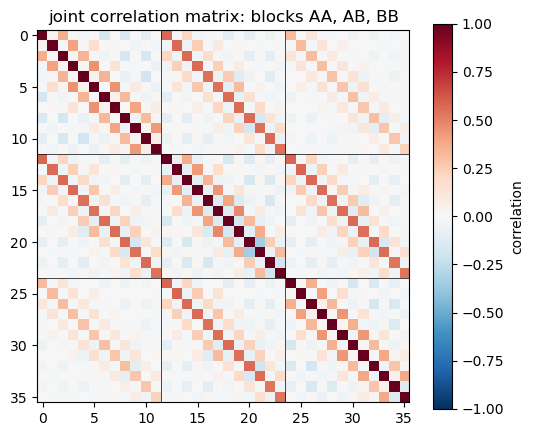

In [6]:
n_out = raw.binning.n_out
corr = cov / np.sqrt(np.outer(np.diag(cov), np.diag(cov)))
plt.figure(figsize=(6, 5)); plt.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r"); plt.colorbar(label="correlation")
for kk in (n_out, 2 * n_out): plt.axhline(kk - 0.5, color="k", lw=0.5); plt.axvline(kk - 0.5, color="k", lw=0.5)
plt.title("joint correlation matrix: blocks AA, AB, BB");

The AA-BB block is non-zero only because the samples share particles (and large-scale modes within
`xi_cut`); for disjoint bins its shot-noise part vanishes. The separate 2-, 3- and 4-point terms are available for
inspection, e.g. the 3-point term per shared-particle catalog and the 2-point term per catalog pair:

In [7]:
c2, c3, c4 = res["c2_terms"], res["c3_terms"], res["c4_term"]
blk = lambda m, a, b: m[a * n_out:(a + 1) * n_out, b * n_out:(b + 1) * n_out]
for name, m in (("C2 (sum over catalog pairs)", c2.sum(axis=0)), ("C3 (sum over shared catalogs)", c3.sum(axis=0)), ("C4", c4)):
    print(f"{name}: diag of AA-AA, AA-BB, AB-AB blocks (ell=0):")
    print("  ", np.diag(blk(m, 0, 0))[::2].round(10), "\n  ", np.diag(blk(m, 0, 2))[::2].round(10), "\n  ", np.diag(blk(m, 1, 1))[::2].round(10))

C2 (sum over catalog pairs): diag of AA-AA, AA-BB, AB-AB blocks (ell=0):
   [1.05825e-05 5.32400e-06 3.28680e-06 2.24460e-06 1.64020e-06 1.25270e-06] 
   [3.3349e-06 1.6176e-06 9.6030e-07 6.3080e-07 4.4010e-07 3.1850e-07] 
   [2.69811e-05 1.27746e-05 7.41980e-06 4.78870e-06 3.29360e-06 2.37930e-06]
C3 (sum over shared catalogs): diag of AA-AA, AA-BB, AB-AB blocks (ell=0):
   [1.23065e-05 5.98880e-06 3.69920e-06 2.49110e-06 1.78250e-06 1.36660e-06] 
   [3.9318e-06 1.8300e-06 1.0746e-06 6.8480e-07 4.7770e-07 3.5560e-07] 
   [3.12666e-05 1.43325e-05 8.28200e-06 5.20920e-06 3.58910e-06 2.62430e-06]
C4: diag of AA-AA, AA-BB, AB-AB blocks (ell=0):
   [6.7498e-06 2.6898e-06 1.4838e-06 1.2502e-06 7.9680e-07 4.9270e-07] 
   [2.2688e-06 9.3430e-07 4.2450e-07 4.3870e-07 4.1040e-07 2.6930e-07] 
   [1.76851e-05 6.99550e-06 3.31430e-06 3.12760e-06 3.21620e-06 1.68150e-06]


## Different tracers

The same interface covers distinct tracers: build one `Catalog` per tracer (each with its own `n_data`) and one
`Sample` per catalog. Shot-noise rescalings are then fitted per catalog in `post_process` (jointly on the full
jackknife covariance by default, or separately with `alpha_method="separate"` as RascalC does).